# **Breast Cancer Classification Using Machine Learning**

**Implementasi Machine Learning Menggunakan Python dan Google Colab**

Pada eksperimen ini, kita akan membandingkan dua algoritma Machine Learning untuk klasifikasi kanker payudara:
1. **Logistic Regression**
2. **Random Forest Classifier**

Kedua model dilatih dan dievaluasi menggunakan pembagian dataset 70% training dan 30% testing untuk mengetahui algoritma mana yang memberikan hasil klasifikasi lebih baik.

Dataset yang digunakan adalah Breast Cancer Wisconsin Dataset yang tersedia pada Scikit-learn. Dataset ini memiliki 569 sampel dengan 30 fitur numerik yang menggambarkan karakteristik sel tumor.

Model akan dilatih untuk mengklasifikasikan tumor ke dalam dua kategori:

*   Malignant (0): Tumor ganas.
*   Benign (1): Tumor jinak.

Proses implementasi dilakukan menggunakan Google Colab sehingga mahasiswa tidak perlu melakukan instalasi Python dan library secara manual pada komputer masing-masing.

# **Step 1: Import Libraries**

Tahap pertama adalah mengimpor library Python yang diperlukan untuk proses pengolahan data, visualisasi, pembangunan model Machine Learning, dan evaluasi performa model.

In [57]:
# Library untuk pengolahan data numerik
import numpy as np
import pandas as pd

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil dataset Breast Cancer dari Scikit-learn
from sklearn.datasets import load_breast_cancer

# Library untuk membagi dataset dan normalisasi data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Library untuk membangun pipeline dan model klasifikasi
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Library untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Semua librari berhasil dimasukkan")

Semua librari berhasil dimasukkan


# **Step 2: Load Dataset**

Pada tahap ini, kita akan memuat Breast Cancer Wisconsin Dataset menggunakan fungsi load_breast_cancer() dari Scikit-learn.

Dataset kemudian dikonversi menjadi DataFrame menggunakan Pandas agar lebih mudah dianalisis.

In [58]:
# Memuat Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Mengambil fitur dan mengubahnya menjadi DataFrame
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Mengambil label atau target kelas
y = data.target

# Menampilkan dimensi dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima sampel pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas target
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

Penjelasan:

*   data.data berisi data numerik yang digunakan sebagai fitur masukan.
*   data.feature_names berisi nama dari masing-masing fitur.
*   data.target berisi label atau kategori tumor.
*   X merupakan variabel yang menyimpan fitur.
*   y merupakan variabel yang menyimpan target klasifikasi.

# **Step 3: Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) merupakan proses eksplorasi dataset untuk memahami karakteristik data sebelum digunakan dalam proses pelatihan model Machine Learning.

Pada tahap ini, kita akan memeriksa:

*   Jumlah sampel pada setiap kelas.
*   Distribusi data.
*   Nilai yang hilang (missing values).
*   Karakteristik fitur yang digunakan.

In [59]:
# Menampilkan informasi umum dataset
print("Dataset Information:")
print(X.info())

# Memeriksa jumlah missing values
print("\nMissing Values:")
print(X.isnull().sum().sum())

# Menampilkan statistik deskriptif
print("\nStatistical Description:")
print(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

Penjelasan:

*   info() menampilkan informasi tipe data dan jumlah data pada setiap fitur.
*   isnull().sum().sum() menghitung total nilai yang hilang.
*   describe() menampilkan statistik deskriptif seperti mean, standar deviasi, minimum, dan maksimum.

**Check Class Distribution**

Selanjutnya, kita akan melihat distribusi jumlah sampel untuk masing-masing kelas tumor.

Class Distribution:
0    212
1    357
Name: count, dtype: int64


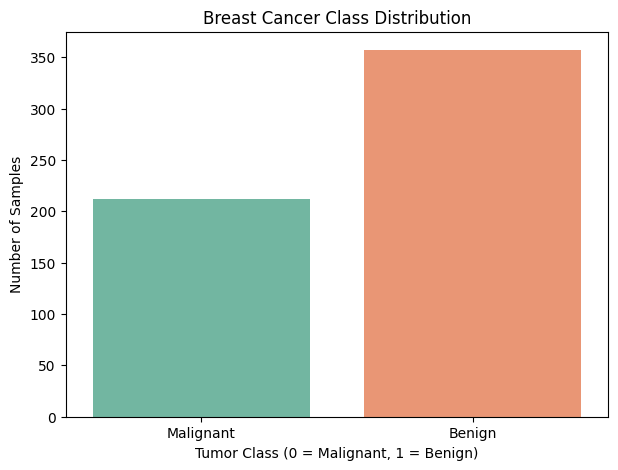

In [60]:
# Menghitung jumlah sampel pada setiap kelas
class_counts = pd.Series(y).value_counts().sort_index()

# Menampilkan jumlah sampel
print("Class Distribution:")
print(class_counts)

# Visualisasi distribusi kelas
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])

plt.show()

Penjelasan:

Visualisasi ini digunakan untuk mengetahui jumlah sampel pada masing-masing kategori.

Informasi distribusi kelas penting karena ketidakseimbangan jumlah sampel dapat memengaruhi proses pelatihan dan evaluasi model.

# **Step 4: Dataset Splitting**

Sebelum membangun model Machine Learning, dataset perlu dibagi menjadi dua bagian:

*   Training Data: Data yang digunakan untuk melatih model.
*   Testing Data: Data yang digunakan untuk menguji kemampuan model terhadap data yang tidak digunakan selama pelatihan.

Pada eksperimen ini, dataset dibagi menjadi:
*   70% Training Data.
*   30% Testing Data.

In [61]:
# Memastikan dataset telah dimuat jika belum ada di memori
try:
    X, y
except NameError:
    from sklearn.datasets import load_breast_cancer
    import pandas as pd
    data = load_breast_cancer()
    X = pd.DataFrame(data.data, columns=data.feature_names)
    y = data.target

# Membagi dataset menjadi training dan testing (70% : 30%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Samples: 398
Testing Samples: 171

Training Features: (398, 30)
Testing Features: (171, 30)


Penjelasan parameter:

X: Dataset fitur

y: Label target

test_size=0.3: 30% data digunakan untuk pengujian

random_state=42: Menjaga konsistensi pembagian data

stratify=y: Mempertahankan proporsi kelas pada training dan testing

# **Step 5: Model Training (Logistic Regression & Random Forest)**

Pada tahap ini kita melatih **dua model** dengan data training yang sama:
1. **Logistic Regression** (dengan StandardScaler dalam Pipeline)
2. **Random Forest Classifier**

Kedua model menggunakan pembagian data yang sama (70% training, 30% testing) agar perbandingan adil.

Sebagai contoh:

- Mean Radius memiliki rentang nilai tertentu.
- Mean Area memiliki rentang nilai yang jauh lebih besar.
- Mean Smoothness memiliki rentang nilai yang relatif kecil.

Perbedaan skala tersebut dapat memengaruhi proses optimasi algoritma Machine Learning seperti Logistic Regression.

Oleh karena itu, kita menggunakan StandardScaler untuk melakukan standardisasi fitur.

Standardisasi dilakukan menggunakan persamaan:

$$
z = \frac{x - \mu}{\sigma}
$$

Keterangan:

- $x$ = Nilai fitur awal.
- $\mu$ = Rata-rata fitur.
- $\sigma$ = Standar deviasi fitur.
- $z$ = Nilai fitur setelah standardisasi.

Dalam implementasi ini, StandardScaler akan dimasukkan ke dalam Pipeline agar proses standardisasi dilakukan secara otomatis.

Catatan: StandardScaler hanya mempelajari parameter dari data training. Data testing hanya ditransformasikan menggunakan parameter tersebut untuk mencegah data leakage.

In [62]:
# ============ MODEL 1: LOGISTIC REGRESSION ============
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
lr_model.fit(X_train, y_train)
print("Logistic Regression Training Completed!")

# ============ MODEL 2: RANDOM FOREST ============
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
print("Random Forest Training Completed!")

Logistic Regression Training Completed!
Random Forest Training Completed!


Penjelasan:

- StandardScaler() melakukan standardisasi fitur.
- LogisticRegression() membangun model klasifikasi.
- max_iter=1000 menentukan jumlah maksimum iterasi optimasi.
- fit() digunakan untuk melatih model berdasarkan data training.

Dengan menggunakan Pipeline, proses standardisasi dan pelatihan model dapat dilakukan dalam satu alur.

# **Step 6: Model Prediction**

Setelah model berhasil dilatih, langkah berikutnya adalah melakukan prediksi menggunakan data testing.

Model akan menghasilkan prediksi kategori tumor berdasarkan karakteristik fitur yang diberikan.

In [63]:
# Prediksi Logistic Regression
y_pred_lr = lr_model.predict(X_test)

# Prediksi Random Forest
y_pred_rf = rf_model.predict(X_test)

print("Prediksi Logistic Regression (10 pertama):")
print(y_pred_lr[:10])
print("\nPrediksi Random Forest (10 pertama):")
print(y_pred_rf[:10])
print("\nLabel Sebenarnya (10 pertama):")
print(y_test[:10])

Prediksi Logistic Regression (10 pertama):
[0 1 1 0 0 0 1 0 1 0]

Prediksi Random Forest (10 pertama):
[0 1 1 0 1 0 1 0 1 0]

Label Sebenarnya (10 pertama):
[0 1 1 0 0 0 1 0 1 0]


Penjelasan:

- predict() digunakan untuk menghasilkan prediksi kelas.
- y_pred berisi hasil prediksi model.
- y_test berisi kelas sebenarnya dari data testing.

Hasil prediksi kemudian dibandingkan dengan label sebenarnya untuk mengetahui tingkat ketepatan model.

# **Step 7: Model Evaluation & Comparison**

Evaluasi dilakukan dengan metrik: Accuracy, Precision, Recall, F1-Score, dan ROC-AUC untuk **kedua model** agar dapat dibandingkan secara objektif.

Pada praktikum ini, kita menggunakan beberapa metrik evaluasi:

- Accuracy.
- Precision.
- Recall.
- F1-Score.
- ROC-AUC.

In [64]:
def evaluate_model(name, y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=0)  # kelas Malignant (0)
    rec = recall_score(y_true, y_pred, pos_label=0)
    f1 = f1_score(y_true, y_pred, pos_label=0)
    print(f"=== {name} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision (Malignant): {prec:.4f}")
    print(f"Recall (Malignant)   : {rec:.4f}")
    print(f"F1-Score (Malignant) : {f1:.4f}")
    if y_prob is not None:
        print(f"ROC-AUC  : {roc_auc_score(y_true, y_prob):.4f}")
    print()
    return acc, prec, rec, f1

**Accuracy**

Accuracy menunjukkan persentase jumlah prediksi yang benar dibandingkan dengan keseluruhan jumlah data pengujian.

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
$$

Keterangan:

- TP = True Positive.
- TN = True Negative.
- FP = False Positive.
- FN = False Negative.

In [65]:
## Probabilitas untuk ROC-AUC
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

metrics_lr = evaluate_model("Logistic Regression", y_test, y_pred_lr, y_prob_lr)
metrics_rf = evaluate_model("Random Forest", y_test, y_pred_rf, y_prob_rf)

=== Logistic Regression ===
Accuracy : 0.9883
Precision (Malignant): 0.9844
Recall (Malignant)   : 0.9844
F1-Score (Malignant) : 0.9844
ROC-AUC  : 0.9981

=== Random Forest ===
Accuracy : 0.9357
Precision (Malignant): 0.9206
Recall (Malignant)   : 0.9062
F1-Score (Malignant) : 0.9134
ROC-AUC  : 0.9913



**Precision, Recall, and F1-Score**

Ketiga metrik ini digunakan untuk memahami performa klasifikasi secara lebih detail.

- Precision: Mengukur ketepatan prediksi pada suatu kelas.
- Recall: Mengukur kemampuan model menemukan seluruh sampel dari suatu kelas.
- F1-Score: Harmonic mean antara precision dan recall.

In [66]:
# Classification Report lengkap
print("===== Classification Report: Logistic Regression =====")
print(classification_report(y_test, y_pred_lr, target_names=data.target_names))

print("===== Classification Report: Random Forest =====")
print(classification_report(y_test, y_pred_rf, target_names=data.target_names))

# Tabel perbandingan
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [metrics_lr[0], metrics_rf[0]],
    "Precision (Malignant)": [metrics_lr[1], metrics_rf[1]],
    "Recall (Malignant)": [metrics_lr[2], metrics_rf[2]],
    "F1-Score (Malignant)": [metrics_lr[3], metrics_rf[3]],
})
print("\n===== Tabel Perbandingan =====")
print(comparison.to_string(index=False))

# Simpan tabel perbandingan
comparison.to_csv("evaluation_results.csv", index=False)

===== Classification Report: Logistic Regression =====
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

===== Classification Report: Random Forest =====
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171


===== Tabel Perbandingan =====
              Model  Accuracy  Precision (Malignant)  Recall (Malignant)  F1-Score (Malignant)
Logistic Regression  0.988304               0.984375            0.984375              0.984375
      Random Forest 

**ROC-AUC**

ROC-AUC digunakan untuk mengukur kemampuan model dalam membedakan dua kelas berdasarkan berbagai nilai threshold.

Nilai AUC berada pada rentang 0 sampai 1.

Semakin mendekati 1, semakin baik kemampuan diskriminasi model.

# **Step 8: Confusion Matrix**

Confusion Matrix merupakan tabel yang digunakan untuk membandingkan hasil prediksi model dengan kelas sebenarnya.

Confusion Matrix memiliki empat komponen utama:
| Komponen | Keterangan |
|:--|:--|
| True Positive (TP) | Sampel positif yang diprediksi positif |
| True Negative (TN) | Sampel negatif yang diprediksi negatif |
| False Positive (FP) | Sampel negatif yang diprediksi positif |
| False Negative (FN) | Sampel positif yang diprediksi negatif |

Pada dataset ini, kelas positif secara default adalah kelas 1 (Benign), sedangkan kelas negatif adalah kelas 0 (Malignant).

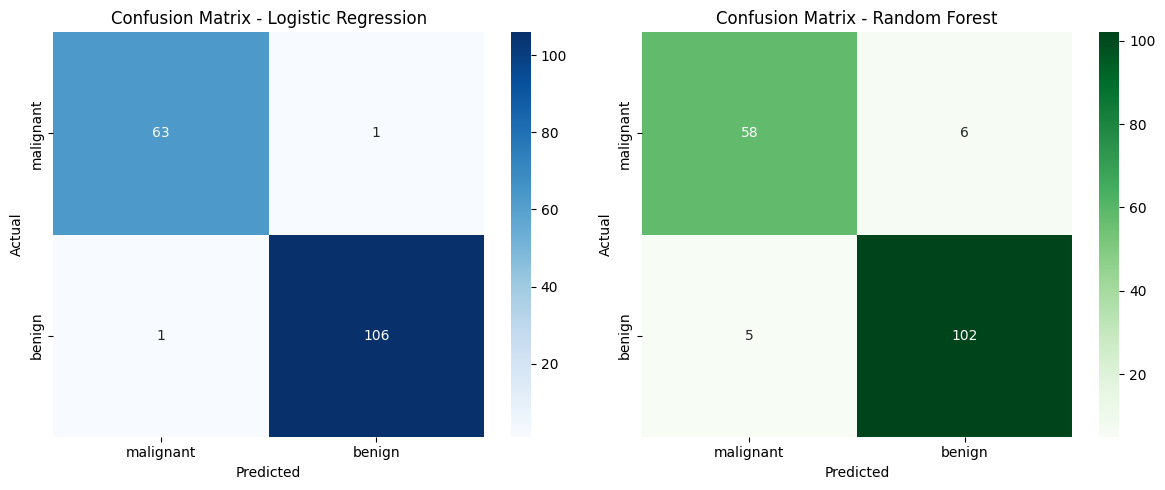

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix - Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues",
            xticklabels=data.target_names, yticklabels=data.target_names, ax=axes[0])
axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Confusion Matrix - Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens",
            xticklabels=data.target_names, yticklabels=data.target_names, ax=axes[1])
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)   # untuk folder results/
plt.show()

Interpretasi:

- Diagonal utama menunjukkan jumlah prediksi yang benar.
- Sel di luar diagonal menunjukkan jumlah kesalahan prediksi.

Dalam konteks klasifikasi kanker, False Negative untuk kelas malignant berarti tumor ganas salah diprediksi sebagai jinak. Kesalahan ini sangat penting untuk diperhatikan karena dapat menyebabkan kondisi berbahaya jika model digunakan dalam konteks klinis.

# **Step 9: Predict a New Sample**

Pada tahap terakhir, kita akan mencoba menggunakan model yang telah dilatih untuk memprediksi satu sampel baru.

Sebagai contoh, kita mengambil satu sampel dari data testing.

In [68]:
sample = X_test.iloc[[0]]

# Menampilkan fitur sampel
print("Input Sample:")
print(sample)

# ============ Prediksi Logistic Regression ============
pred_lr = lr_model.predict(sample)[0]
prob_lr = lr_model.predict_proba(sample)[0]

print("\n=== Prediksi Logistic Regression ===")
print("Hasil:", data.target_names[pred_lr])
print("Probabilitas:")
for class_name, prob in zip(data.target_names, prob_lr):
    print(f"  {class_name}: {round(prob * 100, 2)} %")

# ============ Prediksi Random Forest ============
pred_rf = rf_model.predict(sample)[0]
prob_rf = rf_model.predict_proba(sample)[0]

print("\n=== Prediksi Random Forest ===")
print("Hasil:", data.target_names[pred_rf])
print("Probabilitas:")
for class_name, prob in zip(data.target_names, prob_rf):
    print(f"  {class_name}: {round(prob * 100, 2)} %")

Input Sample:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
14        13.73         22.61            93.6      578.3           0.1131   

    mean compactness  mean concavity  mean concave points  mean symmetry  \
14            0.2293          0.2128              0.08025         0.2069   

    mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
14                 0.07682  ...         15.03          32.01            108.8   

    worst area  worst smoothness  worst compactness  worst concavity  \
14       697.7            0.1651             0.7725           0.6943   

    worst concave points  worst symmetry  worst fractal dimension  
14                0.2208          0.3596                   0.1431  

[1 rows x 30 columns]

=== Prediksi Logistic Regression ===
Hasil: malignant
Probabilitas:
  malignant: 96.79 %
  benign: 3.21 %

=== Prediksi Random Forest ===
Hasil: malignant
Probabilitas:
  malignant: 92.0 %
  benign: 8.0 %


Penjelasan:

1. X_test.iloc[[0]] mengambil satu sampel dari data testing.
2. predict() menghasilkan kategori hasil klasifikasi.
3. predict_proba() menghasilkan probabilitas prediksi untuk masing-masing kelas.
4. data.target_names mengubah label numerik menjadi nama kategori.

Catatan: Model ini digunakan hanya untuk pembelajaran dan demonstrasi Machine Learning. Hasil prediksi tidak boleh digunakan sebagai pengganti diagnosis medis profesional.

# **Step 10: Analisis & Kesimpulan**

## Perbandingan Model
Berdasarkan tabel perbandingan di atas, bandingkan Accuracy, Precision, Recall, dan F1-Score antara Logistic Regression dan Random Forest. Logistic Regression unggul di seluruh metrik: Accuracy 98.83% vs 93.57%, Recall Malignant 98.44% vs 90.62%, F1 98.44% vs 91.34%. Selisih terbesar ada pada Recall LR hanya melewatkan 1 kasus kanker, sedangkan RF melewatkan 6 kasus

## Mengapa Accuracy Saja Tidak Cukup?
Dalam klasifikasi kanker, **accuracy saja tidak cukup** karena:
1. **Dataset tidak seimbang** (212 Malignant vs 357 Benign). Model yang selalu menebak "Benign" akan mendapat akurasi ~63% tetapi tidak berguna.
2. **False Negative berbahaya**
jika kanker (Malignant) diprediksi sebagai Benign, pasien bisa kehilangan nyawa.
3. **Recall** pada kelas Malignant menjadi metrik paling kritis (meminimalkan FN).
4. **Precision** juga penting untuk menghindari False Positive berlebihan yang menyebabkan kecemasan & biaya pemeriksaan tak perlu.
5. **F1-Score** menyeimbangkan Precision & Recall.
6. **ROC-AUC** menilai kemampuan diskriminasi model secara keseluruhan pada berbagai threshold.

## Kesimpulan

Berdasarkan hasil eksperimen dengan pembagian data 70% training dan 30% testing:

| Metrik | Logistic Regression | Random Forest | Pemenang |
|---|---|---|---|
| Accuracy | 0.9883 | 0.9357 | **LR** |
| Precision (Malignant) | 0.9844 | 0.9206 | **LR** |
| Recall (Malignant) | 0.9844 | 0.9062 | **LR** |
| F1-Score (Malignant) | 0.9844 | 0.9134 | **LR** |
| ROC-AUC | 0.9981 | 0.9913 | **LR** |

**Model terbaik: Logistic Regression.**

Logistic Regression unggul di seluruh metrik, terutama **Recall pada kelas Malignant (0.9844 vs 0.9062)**. Dalam konteks deteksi kanker, Recall adalah metrik paling kritis karena mengukur kemampuan model menemukan seluruh kasus kanker (meminimalkan False Negative).

Pada confusion matrix, Random Forest memiliki lebih banyak False Negative untuk kelas Malignant (6 kasus kanker diprediksi jinak), sedangkan Logistic Regression hanya 1 kasus. False Negative pada kanker berpotensi fatal karena pasien tidak mendapat penanganan tepat waktu.

Meskipun Random Forest umumnya lebih robust terhadap data non-linear, pada dataset Breast Cancer Wisconsin ini hubungan antar fitur cenderung linear setelah standardisasi, sehingga Logistic Regression dengan StandardScaler bekerja sangat optimal. Selain itu, Logistic Regression lebih interpretable (koefisien dapat dijelaskan) nilai tambah penting di domain medis.